# Course 12: AI for Accessibility
## Session 9: Reading support: OCR, text-to-speech and simplification

**Goal:** train a digit classifier and a CTC line recognizer, compare them with segmentation on lines joined like Bangla words, normalize text for a speech synthesizer, and check a simplified text for changed facts.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Bangla text as code points
Optical character recognition (OCR) turns an image of text into characters, and text-to-speech (TTS) turns characters into speech. Both work on Unicode **code points**, not on the shapes we see. Three facts about Bangla matter here (Course 5 session 2 has more):

* A **vowel sign** can be drawn on the left of a consonant but is stored after it: in কি, the sign ি appears first on the page but second in memory.
* A **conjunct** (যুক্তাক্ষর) joins consonants with the hasanta (U+09CD, named VIRAMA by Unicode): ক্ষ is ক + ্ + ষ.
* The same text can be stored in different ways: য় is one code point or two, and ো can be one code point or ে + া. Unicode normalization form **NFC** makes each choice consistent, so it must be applied to both sides before comparing OCR output with the truth.

The cell also shows that Python reads Bangla digits as numbers.

In [1]:
import time
import re
import unicodedata
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.set_num_threads(1)
t_start = time.time()
np.random.seed(0)
torch.manual_seed(0)

def show(s):
    return " ".join(f"U+{ord(c):04X}" for c in s)

for word in ["কি", "ক্ষি", "বাংলা"]:
    print(f"{word}: {len(word)} code points: {show(word)}")
one, two = "য়", "য়"                        # য় as one code point, and as য + nukta
print(f"য় stored two ways: equal? {one == two}; after NFC: equal? {unicodedata.normalize('NFC', one) == unicodedata.normalize('NFC', two)} "
      f"(NFC gives {show(unicodedata.normalize('NFC', one))})")
print(f"ে + া after NFC: {show(unicodedata.normalize('NFC', chr(0x09C7) + chr(0x09BE)))} = {unicodedata.name(chr(0x09CB))}")
BN_TO_ASCII = str.maketrans("০১২৩৪৫৬৭৮৯", "0123456789")
ASCII_TO_BN = str.maketrans("0123456789", "০১২৩৪৫৬৭৮৯")
print("৪৫% ->", "৪৫%".translate(BN_TO_ASCII), "| 2026 ->", "2026".translate(ASCII_TO_BN), "| int('৭২') =", int("৭২"))

কি: 2 code points: U+0995 U+09BF
ক্ষি: 4 code points: U+0995 U+09CD U+09B7 U+09BF
বাংলা: 5 code points: U+09AC U+09BE U+0982 U+09B2 U+09BE
য় stored two ways: equal? False; after NFC: equal? True (NFC gives U+09AF U+09BC)
ে + া after NFC: U+09CB = BENGALI VOWEL SIGN O
৪৫% -> 45% | 2026 -> ২০২৬ | int('৭২') = 72


### 2. A digit classifier, standing in for handwritten Bangla digits
Real handwritten Bangla datasets, such as NumtaDB (Alam et al. 2018), need a download (section 6 has a loader). As a stand-in we use scikit-learn's 8 × 8 handwritten digits: a small convolutional network (CNN) trained on two-thirds of them and tested on the rest.

In [2]:
X, y = load_digits(return_X_y=True)
X = (X / 16.0).reshape(-1, 8, 8).astype(np.float32)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.33, random_state=0, stratify=y)

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                                 nn.MaxPool2d(2), nn.Flatten(), nn.Linear(32 * 4 * 4, 64), nn.ReLU(), nn.Linear(64, 10))
    def forward(self, x):
        return self.net(x)

cnn = DigitCNN()
opt = torch.optim.Adam(cnn.parameters(), lr=3e-3)
xt, yt, gen = torch.tensor(X_tr[:, None]), torch.tensor(y_tr), torch.Generator().manual_seed(0)
for epoch in range(15):
    perm = torch.randperm(len(yt), generator=gen)
    for i in range(0, len(yt), 64):
        idx = perm[i:i + 64]
        loss = F.cross_entropy(cnn(xt[idx]), yt[idx])
        opt.zero_grad(); loss.backward(); opt.step()
cnn.eval()
with torch.no_grad():
    acc = (cnn(torch.tensor(X_te[:, None])).argmax(1).numpy() == y_te).mean()
print(f"isolated digits: {len(y_tr)} for training, {len(y_te)} for testing; test accuracy {acc:.3f}")

isolated digits: 1203 for training, 594 for testing; test accuracy 0.973


### 3. Lines of text: spaced, or joined like a Bangla word
A page is read line by line. We make synthetic **lines** of 3 to 8 test digits in two styles:

* **spaced:** 1–3 blank columns between digits, like separate characters;
* **joined:** the digit boxes overlap by 1–3 columns so the ink touches, and a **headline** runs along the top. Bangla words are joined this way: the headline (মাত্রা) connects the letters, and conjuncts and vowel signs reach into their neighbours.

The classic approach **segments then classifies**: remove the headline rows, cut the line wherever a column has no ink, and classify each piece with the CNN from section 2. We score with the **character error rate** (CER): the edit distance between the output and the truth, summed over lines and divided by the number of true characters (session 2), and with **line accuracy**, the share of lines read exactly right.

In [3]:
H = 12                                                      # line height: headline at row 1, digits in rows 2-9

def make_line(X_pool, y_pool, joined, rng):
    n = rng.integers(3, 9)
    ids = rng.integers(0, len(y_pool), n)
    gaps = rng.integers(-3, 0, n) if joined else rng.integers(1, 4, n)
    img = np.zeros((H, 4 + 8 * n + int(gaps[:-1].sum())), np.float32)
    x = 2
    for k, i in enumerate(ids):
        img[2:10, x:x + 8] = np.maximum(img[2:10, x:x + 8], X_pool[i])
        x += 8 + gaps[k]
    if joined:
        img[1, 2:x - gaps[-1]] = 1.0                        # the headline joins the whole word
    return np.clip(img + rng.normal(0, 0.03, img.shape), 0, 1).astype(np.float32), list(y_pool[ids])

def make_lines(X_pool, y_pool, n, joined_share, seed):
    rng = np.random.default_rng(seed)
    return [make_line(X_pool, y_pool, rng.random() < joined_share, rng) for _ in range(n)]

train_lines = make_lines(X_tr, y_tr, 3000, 0.5, seed=1)     # training digits only
test_spaced = make_lines(X_te, y_te, 500, 0.0, seed=2)      # test digits only
test_joined = make_lines(X_te, y_te, 500, 1.0, seed=3)

def edit_distance(a, b):
    d = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        prev, d[0] = d[0], i
        for j in range(1, len(b) + 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (a[i - 1] != b[j - 1]))
    return d[len(b)]

def score(preds, lines):
    edits = sum(edit_distance(p, l[1]) for p, l in zip(preds, lines))
    return edits / sum(len(l[1]) for l in lines), np.mean([p == l[1] for p, l in zip(preds, lines)])

def segment_and_classify(img):
    has_ink = (img[2:] > 0.2).any(0)                        # ignore the headline rows
    pieces, start = [], None
    for c, v in enumerate(list(has_ink) + [False]):
        if v and start is None:
            start = c
        elif not v and start is not None:
            w, box = c - start, np.zeros((8, 8), np.float32)
            if w <= 8:
                box[:, (8 - w) // 2:(8 - w) // 2 + w] = img[2:10, start:c]
            else:                                           # a wide piece: several touching digits, keep the middle
                box = img[2:10, start + (w - 8) // 2:start + (w - 8) // 2 + 8]
            pieces.append(box); start = None
    if not pieces:
        return []
    with torch.no_grad():
        return cnn(torch.tensor(np.array(pieces)[:, None])).argmax(1).tolist()

for name, lines in [("spaced", test_spaced), ("joined", test_joined)]:
    cer, exact = score([segment_and_classify(l[0]) for l in lines], lines)
    print(f"segment-then-classify, {name} lines: CER {cer:.3f}, line accuracy {exact:.3f}")

segment-then-classify, spaced lines: CER 0.071, line accuracy 0.672


segment-then-classify, joined lines: CER 0.602, line accuracy 0.048


### 4. A line recognizer with CTC
A CRNN-style recognizer (Shi et al. 2017) reads a whole line without cutting it: two convolution layers turn the line image into one feature vector for every two columns, a bidirectional GRU reads that sequence, and a linear layer gives each step a probability for the 10 digits and the CTC **blank**. Training uses `nn.CTCLoss`, which sums over all the ways the frames can line up with the true digits (Graves et al. 2006; session 2). Greedy decoding takes the most likely symbol at each step, merges repeats and drops blanks. It trains on 3,000 lines, half of each style, in about a minute.

line reader: 44,907 parameters, trained in 58 s, last loss 0.010


CTC line reader,       spaced lines: CER 0.022, line accuracy 0.890
CTC line reader,       joined lines: CER 0.036, line accuracy 0.824


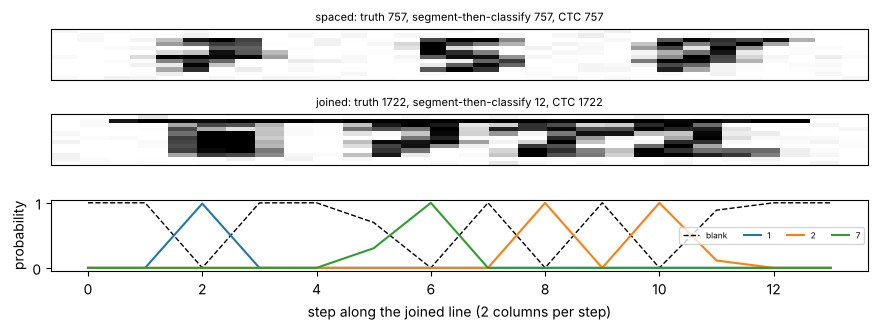

In [4]:
class LineReader(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d((2, 1)),
                                  nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d((2, 2)))   # 12 rows -> 3, width / 2
        self.proj = nn.Linear(32 * 3, 64)
        self.gru = nn.GRU(64, 48, batch_first=True, bidirectional=True)
        self.out = nn.Linear(96, 11)                                                             # digits 0-9 and the blank (10)

    def forward(self, x):
        h = self.conv(x)
        B, C, R, T = h.shape
        h, _ = self.gru(F.relu(self.proj(h.permute(0, 3, 1, 2).reshape(B, T, C * R))))
        return self.out(h).log_softmax(-1)                                                       # (batch, steps, 11)

def batch(lines):
    W = max(l[0].shape[1] for l in lines)
    W += W % 2
    x = np.zeros((len(lines), 1, H, W), np.float32)
    for i, (img, _) in enumerate(lines):
        x[i, 0, :, :img.shape[1]] = img
    steps = torch.tensor([l[0].shape[1] // 2 for l in lines])
    targets = torch.tensor([d for l in lines for d in l[1]])
    return torch.tensor(x), steps, targets, torch.tensor([len(l[1]) for l in lines])

def greedy_decode(log_probs, steps):
    out = []
    for lp, T in zip(log_probs, steps):
        seq, prev = [], None
        for s in lp[:T].argmax(-1).tolist():
            if s != prev and s != 10:
                seq.append(s)
            prev = s
        out.append(seq)
    return out

reader = LineReader()
EPOCHS = 16
opt = torch.optim.Adam(reader.parameters(), lr=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-2, total_steps=EPOCHS * ((len(train_lines) + 63) // 64))
ctc = nn.CTCLoss(blank=10, zero_infinity=True)
rng = np.random.default_rng(5)
t0 = time.time()
for epoch in range(EPOCHS):
    order = rng.permutation(len(train_lines))
    for i in range(0, len(order), 64):
        x, steps, targets, lengths = batch([train_lines[j] for j in order[i:i + 64]])
        loss = ctc(reader(x).permute(1, 0, 2), targets, steps, lengths)                          # CTCLoss wants (steps, batch, symbols)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
reader.eval()
print(f"line reader: {sum(p.numel() for p in reader.parameters()):,} parameters, trained in {time.time() - t0:.0f} s, last loss {loss.item():.3f}")
for name, lines in [("spaced", test_spaced), ("joined", test_joined)]:
    with torch.no_grad():
        x, steps, _, _ = batch(lines)
        cer, exact = score(greedy_decode(reader(x), steps), lines)
    print(f"CTC line reader,       {name} lines: CER {cer:.3f}, line accuracy {exact:.3f}")

fig, ax = plt.subplots(3, 1, figsize=(9, 3.4), gridspec_kw={"height_ratios": [1, 1, 1.4]})
for a, (name, lines) in zip(ax[:2], [("spaced", test_spaced), ("joined", test_joined)]):
    img, truth = lines[0]
    with torch.no_grad():
        x, steps, _, _ = batch([lines[0]])
        pred = greedy_decode(reader(x), steps)[0]
    a.imshow(img, cmap="gray_r", aspect="auto"); a.set_yticks([]); a.set_xticks([])
    a.set_title(f"{name}: truth {''.join(map(str, truth))}, segment-then-classify {''.join(map(str, segment_and_classify(img)))}, "
                f"CTC {''.join(map(str, pred))}", fontsize=8)
with torch.no_grad():
    probs = reader(batch([test_joined[0]])[0])[0].exp().numpy()
ax[2].plot(probs[:, 10], "k--", lw=1, label="blank")
for d in sorted(set(test_joined[0][1])):
    ax[2].plot(probs[:, d], lw=1.5, label=str(d))
ax[2].set_xlabel("step along the joined line (2 columns per step)"); ax[2].set_ylabel("probability")
ax[2].legend(fontsize=6, ncol=6, loc="center right")
plt.tight_layout(); plt.show()

### 5. Text normalization for a speech synthesizer
Before a TTS voice can speak a sentence, **non-standard words** (numbers, currency, percentages, times, abbreviations) must become ordinary words (Sproat et al. 2001). The right reading depends on the place and the role of the number:

* Bangladesh writes and reads large numbers in **lakh** (1,00,000) and **crore** (1,00,00,000), so "Tk 2,50,000" should be read "two lakh fifty thousand taka", not "two hundred and fifty thousand taka".
* "2026" is "twenty twenty-six" as a year but "two thousand and twenty-six" as a quantity.
* Bangla digits in English text, such as ৪৫%, must be converted first.

We write an English number expander (British style, with "and", as used in Bangladesh) and test it. **Bangla number words are harder:** the words for 0 to 99 are irregular (১১ এগারো, ২১ একুশ, ২৫ পঁচিশ, ৫৫ পঞ্চান্ন, ৯৯ নিরানব্বই), so they need a lookup table, which assignment 9 builds from a verified source.

In [5]:
ONES = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten", "eleven", "twelve",
        "thirteen", "fourteen", "fifteen", "sixteen", "seventeen", "eighteen", "nineteen"]
TENS = ["", "", "twenty", "thirty", "forty", "fifty", "sixty", "seventy", "eighty", "ninety"]

def below_100(n):
    return ONES[n] if n < 20 else TENS[n // 10] + ("" if n % 10 == 0 else "-" + ONES[n % 10])

def below_1000(n):
    h, r = divmod(n, 100)
    if h == 0:
        return below_100(r)
    return ONES[h] + " hundred" + ("" if r == 0 else " and " + below_100(r))

def number_to_words(n, system="south_asian"):
    if n == 0:
        return "zero"
    units = [(10**7, "crore"), (10**5, "lakh"), (1000, "thousand")] if system == "south_asian" else \
            [(10**9, "billion"), (10**6, "million"), (1000, "thousand")]
    parts = []
    for size, name in units:
        if n >= size:
            q, n = divmod(n, size)
            parts.append(number_to_words(q, system) + " " + name)
    if n:
        parts.append(("and " + below_100(n)) if parts and n < 100 else below_1000(n))
    return " ".join(parts)

def year_to_words(n):
    if 2000 <= n <= 2009:
        return number_to_words(n)
    hi, lo = divmod(n, 100)
    return below_100(hi) + " " + ("hundred" if lo == 0 else below_100(lo) if lo >= 10 else "oh " + ONES[lo])

tests = [(0, "zero", None), (13, "thirteen", None), (21, "twenty-one", None), (105, "one hundred and five", None),
         (1005, "one thousand and five", None), (1250, "one thousand two hundred and fifty", None),
         (250000, "two lakh fifty thousand", "two hundred and fifty thousand"),
         (12500000, "one crore twenty-five lakh", "twelve million five hundred thousand")]
failed = 0
for n, sa, intl in tests:
    for system, want in [("south_asian", sa), ("international", intl or sa)]:
        got = number_to_words(n, system)
        if got != want:
            failed += 1; print(f"FAIL {n} ({system}): {got!r}, expected {want!r}")
for n, want in [(1971, "nineteen seventy-one"), (2026, "twenty twenty-six"), (2005, "two thousand and five"), (1905, "nineteen oh five")]:
    if year_to_words(n) != want:
        failed += 1; print(f"FAIL year {n}: {year_to_words(n)!r}")
print(f"{2 * len(tests) + 4 - failed} of {2 * len(tests) + 4} number tests passed")

ABBREVIATIONS = {"Dr.": "Doctor", "No.": "number", "Rd.": "Road"}

def normalize_for_tts(text, system="south_asian"):
    text = unicodedata.normalize("NFC", text).translate(BN_TO_ASCII)
    for short, full in ABBREVIATIONS.items():
        text = text.replace(short, full)
    words = lambda s: number_to_words(int(s.replace(",", "")), system)
    text = re.sub(r"(?:Tk\.?|৳)\s?(\d[\d,]*)", lambda m: words(m.group(1)) + " taka", text)
    text = re.sub(r"(\d+)%", lambda m: words(m.group(1)) + " percent", text)
    text = re.sub(r"\b(\d{1,2}):(\d\d)\b", lambda m: words(m.group(1)) + ("" if m.group(2) == "00" else " " +
                  (below_100(int(m.group(2))) if int(m.group(2)) >= 10 else "oh " + ONES[int(m.group(2))])), text)
    text = re.sub(r"\b(in|since|of) (1[1-9]\d\d|20\d\d)\b", lambda m: m.group(1) + " " + year_to_words(int(m.group(2))), text)
    return re.sub(r"\d[\d,]*", lambda m: words(m.group(0)), text)

for s in ["Dr. Karim paid Tk 2,50,000 for 3 hearing aids in 2026.",
          "The bus to Mirpur No. 10 leaves at 7:05 from Lake Rd.",
          "Only ৪৫% of the 1,250 forms were read correctly."]:
    print(f"{s}\n  -> {normalize_for_tts(s)}")
print("international system for the first one:\n  ->", normalize_for_tts("Dr. Karim paid Tk 2,50,000 for 3 hearing aids in 2026.", "international"))

20 of 20 number tests passed
Dr. Karim paid Tk 2,50,000 for 3 hearing aids in 2026.
  -> Doctor Karim paid two lakh fifty thousand taka for three hearing aids in twenty twenty-six.
The bus to Mirpur No. 10 leaves at 7:05 from Lake Rd.
  -> The bus to Mirpur number ten leaves at seven oh five from Lake Road
Only ৪৫% of the 1,250 forms were read correctly.
  -> Only forty-five percent of the one thousand two hundred and fifty forms were read correctly.
international system for the first one:
  -> Doctor Karim paid two hundred and fifty thousand taka for three hearing aids in twenty twenty-six.


### 6. Checking a simplified text for changed facts
Easy-to-read versions help people with intellectual disabilities and people with low literacy, and large language models can write them quickly. But a simplifier can drop or change facts while sounding fluent. A cheap automatic check compares the numbers in the two texts; the cell also prints two simple readability measures, the average sentence length in words and the average word length in letters. Watch what the number check catches and what it misses.

In [6]:
original = ("Take 2 tablets every 8 hours with water. Do not take more than 6 tablets in 24 hours. "
            "Stop taking them and see a doctor if you get a rash.")
simplified = {"careful": ("Take 2 tablets. Wait 8 hours before you take 2 more. Take no more than 6 tablets in one day (24 hours). "
                          "Did you get a rash? Stop. See a doctor."),
              "wrong": "Take 2 tablets every 6 hours. Stop if you get a rash."}

def numbers(text):
    return re.findall(r"\d+", text.translate(BN_TO_ASCII))

def readability(text):
    sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    words = re.findall(r"[A-Za-z]+", text)
    return len(words) / len(sentences), np.mean([len(w) for w in words])

print(f"original:   {readability(original)[0]:.1f} words per sentence, {readability(original)[1]:.2f} letters per word; numbers {numbers(original)}")
for name, text in simplified.items():
    wps, lpw = readability(text)
    missing = sorted(set(numbers(original)) - set(numbers(text)), key=int)
    new = sorted(set(numbers(text)) - set(numbers(original)), key=int)
    print(f"{name:10s}: {wps:.1f} words per sentence, {lpw:.2f} letters per word; numbers {numbers(text)}; "
          f"missing {missing}, new {new}")
print("the 'wrong' version passes the new-number test, yet 2 tablets every 6 hours is", 2 * 24 // 6, "tablets a day, above the limit of 6")
print(f"runtime so far {time.time() - t_start:.0f} s")

original:   8.7 words per sentence, 3.88 letters per word; numbers ['2', '8', '6', '24']
careful   : 4.3 words per sentence, 3.81 letters per word; numbers ['2', '8', '2', '6', '24']; missing [], new []
wrong     : 5.0 words per sentence, 3.80 letters per word; numbers ['2', '6']; missing ['8', '24'], new []
the 'wrong' version passes the new-number test, yet 2 tablets every 6 hours is 8 tablets a day, above the limit of 6
runtime so far 63 s


### 7. Real OCR (NOT RUN here)
Tesseract is an open-source OCR engine whose LSTM line recognizer, like ours, reads whole lines; its Bengali model has the language code `ben`. NumtaDB is a collection of handwritten Bangla digits published on Kaggle by Bengali.AI. Both need downloads.

In [ ]:
# NOT RUN: needs the Tesseract program with Bengali data (apt-get install tesseract-ocr tesseract-ocr-ben), pytesseract and Pillow
from PIL import Image
import pytesseract

page = Image.open("scanned_page.png")                          # a page you are allowed to use, with a typed transcript
text = pytesseract.image_to_string(page, lang="ben", config="--oem 1 --psm 6")   # LSTM engine; one uniform block of text
text = unicodedata.normalize("NFC", text)
truth = unicodedata.normalize("NFC", open("scanned_page.txt", encoding="utf-8").read())
print(text[:300])
print(f"CER {edit_distance(list(text), list(truth)) / len(truth):.3f}")    # normalize both sides before scoring

In [ ]:
# NOT RUN: needs the NumtaDB dataset of handwritten Bangla digits from Kaggle (Bengali.AI) and Pillow
import pandas as pd
from PIL import Image

root = "/kaggle/input/numta"                                   # where the dataset is mounted; adjust for your copy
meta = pd.read_csv(f"{root}/training-a.csv")                   # one CSV per source folder: training-a to training-e
print(meta.columns.tolist())                                   # check the column names (an image file name and a digit label)
imgs = np.stack([np.asarray(Image.open(f"{root}/training-a/{f}").convert("L").resize((32, 32)), dtype=np.float32) / 255.0
                 for f in meta["filename"][:5000]])
labels = meta["digit"].values[:5000]
imgs = 1.0 - imgs                                               # dark ink on white paper -> bright ink, as in load_digits
print(imgs.shape, np.bincount(labels))                          # then train a CNN like DigitCNN with a 32 x 32 input

### 8. Exercises

In [7]:
# TODO: Bangla number words. Build a lookup table for 0-99 from a verified source (for example a Bangla grammar book
# or a Bangla Academy dictionary), then write bangla_number_words(n) for 0 <= n < 1,00,00,00,000 using শত (hundred),
# হাজার (thousand), লাখ (lakh) and কোটি (crore). Add at least 10 tests, including 0, 11, 21, 99, 100, 101, 1,00,000.
BANGLA_0_99 = {}                     # fill in: {0: "শূন্য", 1: "এক", ...}
def bangla_number_words(n):
    return None                      # replace with your code

r = bangla_number_words(2026)
print("not done yet" if r is None else r)

not done yet


In [8]:
# TODO: how far does the line reader generalize? Make 300 test lines of 9-12 digits (longer than any training line),
# and 300 normal-length lines with stronger noise (sigma 0.15 instead of 0.03). Report the CER and line accuracy of
# the CTC reader and of segment-then-classify on each. Which failures would a blind reader notice, and which not?
def generalization_test():
    return None                      # replace with your code; return a small table of results

r = generalization_test()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **What you see is not what is stored.** কি is 2 code points, and its vowel sign is stored after the consonant although it is drawn before it; ক্ষি is 4 code points. The two forms of য় were unequal until NFC turned both into U+09AF U+09BC, and ে + া became the single code point U+09CB. Python's `int()` even reads Bangla digits: `int('৭২')` gave 72.
2. **Isolated digits are easy here.** The small CNN classified 0.973 of 594 test digits correctly.
3. **Segmentation fails as soon as characters touch.** Segment-then-classify had a CER of 0.071 (line accuracy 0.672) on spaced lines, but 0.602 (0.048) on joined lines, where touching digits merge into one piece: in the example it read the joined line 1722 as 12. Even spaced lines did worse than isolated digits, because some digits break into two pieces and a re-centred piece no longer looks like the training digits.
4. **The CTC line reader needs no segmentation.** With 44,907 parameters and about a minute of training it reached a CER of 0.022 (line accuracy 0.890) on spaced lines and 0.036 (0.824) on joined lines, and read 1722 correctly. Its probability plot shows one spike per digit, with a blank spike between the two 2s: the blank is what lets CTC write a double letter (session 2). Line accuracy is still far from 1: one wrong digit spoils a line, and a phone number with one wrong digit is useless.
5. **Normalization rules work, and they are fragile.** All 20 number tests passed. "Tk 2,50,000" became "two lakh fifty thousand taka" in the South Asian system and "two hundred and fifty thousand taka" in the international one, "in 2026" became "in twenty twenty-six" and ৪৫% became "forty-five percent". But expanding "Rd." swallowed the full stop at the end of the second sentence, and the rule for "No." would also fire on "No. I don't agree". Every rule needs tests on real text.
6. **A fluent simplification can be dangerous.** The careful version halved the sentence length (8.7 to 4.3 words per sentence) and kept every number. The wrong version dropped 8 and 24, which the number check caught, but it added no new number, and its "2 tablets every 6 hours" means 8 tablets a day, above the limit of 6. Word length hardly changed (3.88, 3.81 and 3.80 letters): these measures count length, not meaning or safety, so a person must check the meaning.